# Vehicle Insurance Claim Fraud Detection
## Classification using five Machine Learning algorithms

**Course:** Machine Learning – Assignment 2  
**Programme:** BITS Pilani WILP  
**Student ID:** 2025NS04074  
**Dataset:** Kaggle – Vehicle Claim Fraud Detection  
**Target field:** `FraudFound_P`

This notebook follows the practical sequence used in the Machine Learning laboratory sessions: understand the data, prepare it, split the observations, build classifiers, make predictions, and assess model performance.

The purpose is to compare five classifiers on one common dataset and one common held-out test set. The notebook records the experiment; interpretations must be completed after reviewing the actual outputs.

# TABLE OF CONTENTS

1. [Problem definition](#part-1)
2. [Import libraries and load data](#part-2)
3. [Understand the dataset](#part-3)
4. [Data quality checks](#part-4)
5. [Exploratory data analysis](#part-5)
6. [Prepare features and target](#part-6)
7. [Preprocess the data](#part-7)
8. [Split into training and testing sets](#part-8)
9. [Logistic Regression](#part-9)
10. [Decision Tree using Entropy](#part-10)
11. [K-Nearest Neighbours](#part-11)
12. [Gaussian Naive Bayes](#part-12)
13. [Support Vector Machine](#part-13)
14. [Compare all five classifiers and calculate the six required metrics](#part-14)
15. [Confusion matrices and ROC curves](#part-15)
16. [Save models and test data](#part-16)
17. [Model-wise observations, overall winner, limitations and submission evidence](#part-17)

---

<a id="part-1"></a>
# <span style="color:#C00000">1. PROBLEM DEFINITION</span>

Vehicle insurance claim fraud is a relevant classification problem because historical claim records may contain patterns associated with fraudulent and non-fraudulent claims. A classifier can help identify claims that may deserve closer examination.

**Problem statement:** Use the available claim, policy, vehicle and claimant attributes to classify a record as:

- `0` – Non-fraudulent claim
- `1` – Fraudulent claim

**Business use:** The output is a screening signal for prioritising manual investigation. A model prediction is not proof of fraud and must not be used as an automatic reason to reject a claim.

**Dataset boundary:** This is the historical Kaggle vehicle-claim dataset. It is not ICICI Lombard proprietary data and should not be described as an Indian insurer dataset.

<a id="part-2"></a>
# <span style="color:#C00000">2. IMPORT LIBRARIES AND LOAD DATA</span>

The libraries below support data handling, charts, preprocessing, the five classifiers and model assessment. The dataset is read from the project `data` folder so the notebook does not depend on a temporary download path.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore",message="Could not find the number of physical cores.*",category=UserWarning,)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "FraudFound_P"

# Resolve the project directory whether Jupyter was opened from the root or notebooks folder.
CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR if (CURRENT_DIR / "data").is_dir() else CURRENT_DIR.parent
DATA_FILE = PROJECT_DIR / "data" / "fraud_oracle.csv"

print("Project directory:", PROJECT_DIR)
print("Dataset file:", DATA_FILE)

Project directory: d:\ML-Assignment2-2025NS04074\1_ML-Assignment2-2025NS04074-Final
Dataset file: d:\ML-Assignment2-2025NS04074\1_ML-Assignment2-2025NS04074-Final\data\fraud_oracle.csv


In [ ]:
claims = pd.read_csv(DATA_FILE)
print("Dataset loaded.")
print("Number of records:", claims.shape[0])
print("Number of columns:", claims.shape[1])

# Configure Pandas display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

display(claims.head())

Dataset loaded.
Number of records: 15420
Number of columns: 33


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [4]:
# Dataset eligibility checks
candidate_predictors = claims.drop(columns=[TARGET, "PolicyNumber"], errors="ignore")
print("Dataset eligibility")
print("Rows:", len(claims))
print("Predictor features (excluding target and PolicyNumber):", candidate_predictors.shape[1])

assert len(claims) >= 500, "The dataset must contain at least 500 instances."
assert candidate_predictors.shape[1] >= 12, "The dataset must contain at least 12 input features."
assert TARGET in claims.columns, f"Target column {TARGET!r} is not present."
assert claims[TARGET].dropna().nunique() == 2, "The target must contain exactly two classes."

print("Dataset meets the minimum instance and feature requirements.")

Dataset eligibility
Rows: 15420
Predictor features (excluding target and PolicyNumber): 31
Dataset meets the minimum instance and feature requirements.


<a id="part-3"></a>
# <span style="color:#C00000">3. UNDERSTAND THE DATASET</span>

The initial data review covers the sample, dimensions, column names, data types and summary values before the data is prepared.

In [5]:
print("Dataset dimensions:", claims.shape)
print("\nColumn names:")
print(claims.columns.tolist())
print("\nData types and non-null counts:")
claims.info()

Dataset dimensions: (15420, 33)

Column names:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-

In [6]:
display(claims.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Month,15420,12,Jan,1411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonth,15420.0,NaN,NaN,NaN,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
DayOfWeek,15420,7,Monday,2616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make,15420,19,Pontiac,3837,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccidentArea,15420,2,Urban,13822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DayOfWeekClaimed,15420,8,Monday,3757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthClaimed,15420,13,Jan,1446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonthClaimed,15420.0,NaN,NaN,NaN,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Sex,15420,2,Male,13000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,15420,4,Married,10625,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Number of distinct values in each column:")
display(claims.nunique(dropna=False).sort_values(ascending=False).to_frame("Distinct values"))

Number of distinct values in each column:


,Distinct values
PolicyNumber,15420
Age,66
Make,19
RepNumber,16
MonthClaimed,13
Month,12
PolicyType,9
AgeOfPolicyHolder,9
DayOfWeekClaimed,8
AgeOfVehicle,8


<a id="part-4"></a>
# <span style="color:#C00000">4. DATA QUALITY CHECKS</span>

Check missing values, duplicate rows, target validity and unusual category values. The result of each check should be reviewed before proceeding; do not remove records without a reason.

In [8]:
missing_summary = claims.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].to_frame("Missing values"))
print("Total missing cells:", int(claims.isna().sum().sum()))
print("Duplicate complete rows:", int(claims.duplicated().sum()))

,Missing values


Total missing cells: 0
Duplicate complete rows: 0


In [9]:
print("Target values:", sorted(claims[TARGET].dropna().unique().tolist()))
print("Target missing values:", claims[TARGET].isna().sum())
print("Target counts:")
display(claims[TARGET].value_counts(dropna=False).sort_index())

Target values: [0, 1]
Target missing values: 0
Target counts:


FraudFound_P
0    14497
1      923
Name: count, dtype: int64

In [10]:
# Review the distinct values in categorical columns for unexpected labels.
categorical_columns_raw = claims.select_dtypes(exclude="number").columns.tolist()
for column in categorical_columns_raw:
    print("\n", column)
    print(claims[column].value_counts(dropna=False).head(20))


 Month
Month
Jan    1411
May    1367
Mar    1360
Jun    1321
Oct    1305
Dec    1285
Apr    1280
Feb    1266
Jul    1257
Sep    1240
Nov    1201
Aug    1127
Name: count, dtype: int64

 DayOfWeek
DayOfWeek
Monday       2616
Friday       2445
Tuesday      2300
Thursday     2173
Wednesday    2159
Saturday     1982
Sunday       1745
Name: count, dtype: int64

 Make
Make
Pontiac      3837
Toyota       3121
Honda        2801
Mazda        2354
Chevrolet    1681
Accura        472
Ford          450
VW            283
Dodge         109
Saab          108
Mercury        83
Saturn         58
Nisson         30
BMW            15
Jaguar          6
Porche          5
Mecedes         4
Ferrari         2
Lexus           1
Name: count, dtype: int64

 AccidentArea
AccidentArea
Urban    13822
Rural     1598
Name: count, dtype: int64

 DayOfWeekClaimed
DayOfWeekClaimed
Monday       3757
Tuesday      3375
Wednesday    2951
Thursday     2660
Friday       2497
Saturday      127
Sunday         52
0               

### Review of unusual or sentinel values

The following checks highlight values that may need domain interpretation. They are reported for review and are not automatically deleted or recoded.

In [13]:
review_columns = ["Age", "MonthClaimed", "DayOfWeekClaimed", "Days_Policy_Accident",
                  "Days_Policy_Claim", "NumberOfSuppliments", "AddressChange_Claim"]
for field in review_columns:
    if field in claims.columns:
        print(f"\\n{field}:")
        print(claims[field].value_counts(dropna=False).head(20))

if "Age" in claims.columns:
    print("\\nRecords with Age = 0:", int((claims["Age"] == 0).sum()))
if "MonthClaimed" in claims.columns:
    print("Records with MonthClaimed = '0':",
          int((claims["MonthClaimed"].astype(str) == "0").sum()))

\nAge:
Age
30    596
33    574
34    573
35    569
28    560
29    552
31    550
32    544
27    540
26    535
39    435
41    423
44    411
37    410
36    406
43    404
42    401
45    386
38    384
40    383
Name: count, dtype: int64
\nMonthClaimed:
MonthClaimed
Jan    1446
May    1411
Mar    1348
Oct    1339
Jun    1293
Feb    1287
Nov    1285
Apr    1271
Sep    1242
Jul    1225
Dec    1146
Aug    1126
0         1
Name: count, dtype: int64
\nDayOfWeekClaimed:
DayOfWeekClaimed
Monday       3757
Tuesday      3375
Wednesday    2951
Thursday     2660
Friday       2497
Saturday      127
Sunday         52
0               1
Name: count, dtype: int64
\nDays_Policy_Accident:
Days_Policy_Accident
more than 30    15247
none               55
8 to 15            55
15 to 30           49
1 to 7             14
Name: count, dtype: int64
\nDays_Policy_Claim:
Days_Policy_Claim
more than 30    15342
15 to 30           56
8 to 15            21
none                1
Name: count, dtype: int64
\nNumberOfS

**Identifier review:** `PolicyNumber` is a record identifier, not a general behavioural attribute. It will be excluded from the model input. Other fields such as `RepNumber` are retained at this stage; their predictive usefulness and possible operational bias should be considered when interpreting results.

<a id="part-5"></a>
# <span style="color:#C00000">5. EXPLORATORY DATA ANALYSIS</span>

The plots in this section are used to understand the class balance and how selected claim attributes are distributed. They are descriptive summaries, not evidence that a field causes fraud.

,Records,Percentage
FraudFound_P,,
0,14497,94.01
1,923,5.99


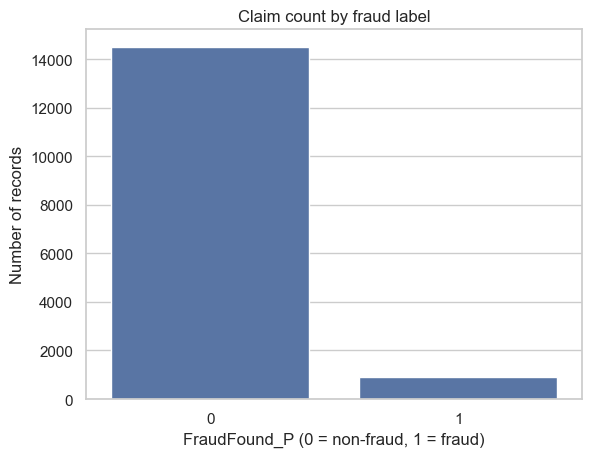

In [14]:
target_count = claims[TARGET].value_counts().sort_index()
target_percent = claims[TARGET].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"Records": target_count, "Percentage": target_percent.round(2)}))
ax = sns.countplot(data=claims, x=TARGET)
ax.set_title("Claim count by fraud label")
ax.set_xlabel("FraudFound_P (0 = non-fraud, 1 = fraud)")
ax.set_ylabel("Number of records")
plt.show()

In [15]:
numeric_columns = claims.select_dtypes(include="number").columns.tolist()
numeric_predictors_raw = [c for c in numeric_columns if c not in [TARGET, "PolicyNumber"]]
display(claims[numeric_predictors_raw].describe().T)

,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Age,15420.0,39.855707,13.492377,0.0,31.0,38.0,48.0,80.0
RepNumber,15420.0,8.483268,4.599948,1.0,5.0,8.0,12.0,16.0
Deductible,15420.0,407.704280,43.950998,300.0,400.0,400.0,400.0,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.0,2.0,3.0,4.0
Year,15420.0,1994.866472,0.803313,1994.0,1994.0,1995.0,1996.0,1996.0


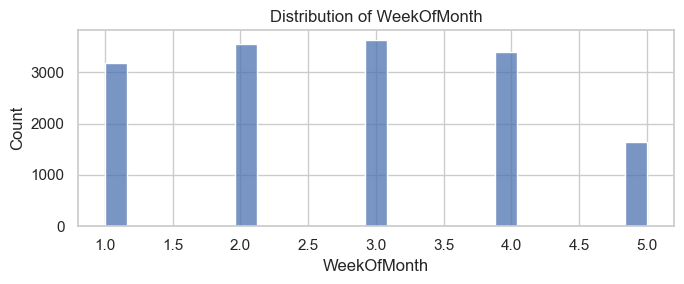

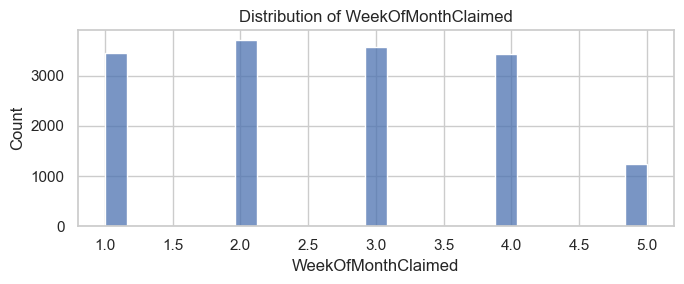

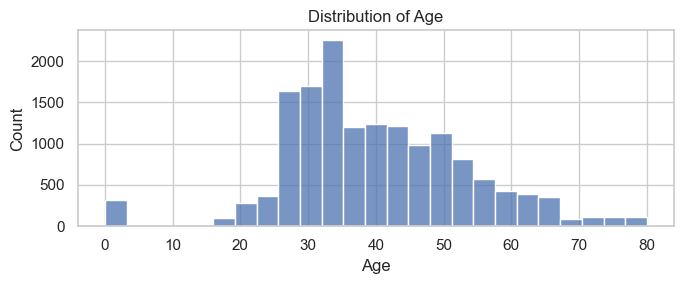

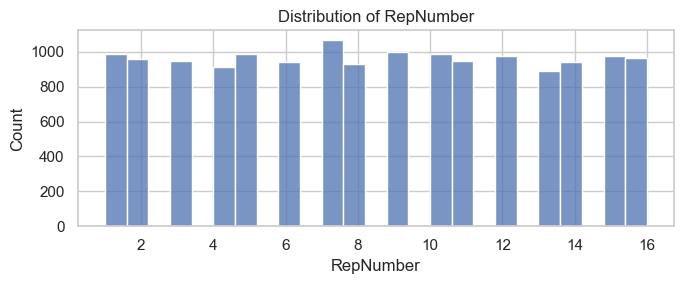

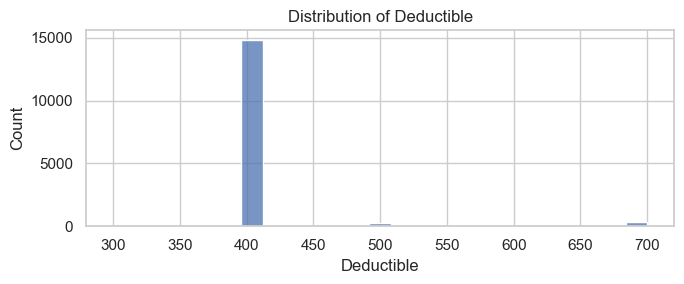

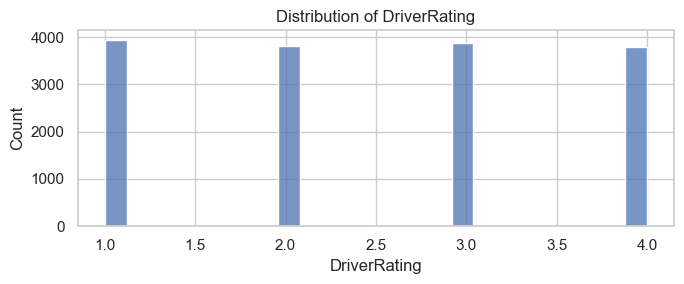

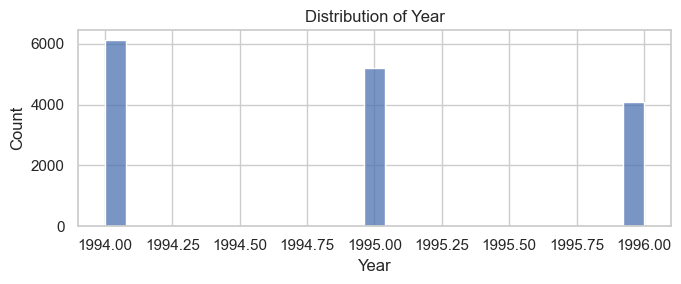

In [16]:
# Inspect distributions of numeric predictors.
for field in numeric_predictors_raw:
    plt.figure(figsize=(7, 3))
    sns.histplot(data=claims, x=field, bins=25, kde=False)
    plt.title("Distribution of " + field)
    plt.tight_layout()
    plt.show()

In [17]:
# Compare fraud proportion across a few business-readable categorical fields.
fields_to_compare = ["AccidentArea", "Fault", "VehicleCategory", "AgentType", "BasePolicy"]
for field in fields_to_compare:
    if field in claims.columns:
        fraud_by_group = claims.groupby(field, dropna=False)[TARGET].agg(
            claim_count="count", fraud_rate="mean"
        ).sort_values("fraud_rate", ascending=False)
        display(fraud_by_group.style.format({"fraud_rate": "{:.2%}"}).set_caption("Fraud proportion by " + field))

,claim_count,fraud_rate
AccidentArea,,
Rural,1598,8.32%
Urban,13822,5.72%


,claim_count,fraud_rate
Fault,,
Policy Holder,11230,7.89%
Third Party,4190,0.88%


,claim_count,fraud_rate
VehicleCategory,,
Utility,391,11.25%
Sedan,9671,8.22%
Sport,5358,1.57%


,claim_count,fraud_rate
AgentType,,
External,15179,6.05%
Internal,241,1.66%


,claim_count,fraud_rate
BasePolicy,,
All Perils,4449,10.16%
Collision,5962,7.30%
Liability,5009,0.72%


<a id="part-6"></a>
# <span style="color:#C00000">6. PREPARE FEATURES AND TARGET</span>

The target is separated from the predictors. The policy number is removed from the predictors because it identifies a policy record rather than describing claim characteristics.

In [18]:
X = claims.drop(columns=[TARGET, "PolicyNumber"], errors="ignore").copy()
y = claims[TARGET].astype(int).copy()

print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)
print("Target labels:", sorted(y.unique()))
print("Predictor fields:")
print(X.columns.tolist())

Predictor matrix: (15420, 31)
Target vector: (15420,)
Target labels: [np.int64(0), np.int64(1)]
Predictor fields:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']


<a id="part-7"></a>
# <span style="color:#C00000">7. PREPROCESS THE DATA</span>

The preprocessing workflow covers missing-value treatment, categorical encoding and feature scaling. Here the transformations are placed in a `ColumnTransformer` and fitted as part of each model pipeline. This keeps the training and testing process consistent and prevents the test set from influencing imputation, encoding or scaling parameters.

- Numeric fields: median imputation followed by standardisation.
- Categorical fields: most-frequent imputation followed by one-hot encoding.
- `handle_unknown="ignore"` allows the model to process a category not seen during training.

In [19]:
numeric_fields = X.select_dtypes(include="number").columns.tolist()
categorical_fields = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric fields:", numeric_fields)
print("\nCategorical fields:", categorical_fields)
print("\nNumber of numeric fields:", len(numeric_fields))
print("Number of categorical fields:", len(categorical_fields))

Numeric fields: ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'RepNumber', 'Deductible', 'DriverRating', 'Year']

Categorical fields: ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']

Number of numeric fields: 7
Number of categorical fields: 24


In [20]:
numeric_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median")),
    ("standardise", StandardScaler())
])

categorical_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

def make_preprocessor():
    numeric_steps = Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="median")),
        ("standardise", StandardScaler())
    ])
    categorical_steps = Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_steps, numeric_fields),
        ("categorical", categorical_steps, categorical_fields)
    ], remainder="drop", sparse_threshold=0)

print("Preprocessing function is ready.")

Preprocessing function is ready.


<a id="part-8"></a>
# <span style="color:#C00000">8. SPLIT INTO TRAINING AND TESTING SETS</span>

A stratified split is used so that the proportion of fraud and non-fraud records is approximately maintained in both partitions. All five algorithms will use this same split.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts().sort_index().to_frame("Training records"))
print("\nTesting target distribution:")
display(y_test.value_counts().sort_index().to_frame("Testing records"))

Training features: (12336, 31)
Testing features: (3084, 31)

Training target distribution:


,Training records
FraudFound_P,
0,11598
1,738



Testing target distribution:


,Testing records
FraudFound_P,
0,2899
1,185


### Model configuration

| Classifier | Configuration used |
|---|---|
| Logistic Regression | `max_iter=2000`, `class_weight="balanced"` |
| Decision Tree | `criterion="entropy"`, `max_depth=8`, `min_samples_leaf=5`, `class_weight="balanced"` |
| KNN | `k` selected from 3, 5, 7, 9, 11 and 15 using 5-fold stratified cross-validation on training data; F1 is the selection score |
| Gaussian Naive Bayes | `GaussianNB()` |
| SVM | RBF kernel, `C=1.0`, `gamma="scale"`, `class_weight="balanced"`, probability estimates enabled |

The configurations above are used consistently in this notebook and in the companion training script.

<a id="part-9"></a>
# <span style="color:#C00000">9. LOGISTIC REGRESSION</span>

Binary Logistic Regression estimates classification, prediction and performance assessment. The scikit-learn implementation is used here, with the preprocessing steps included in the pipeline. `class_weight="balanced"` adjusts the fitting weights to account for the lower frequency of fraud cases.

In [22]:
lr_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

lr_pipeline.fit(X_train, y_train)
lr_prediction = lr_pipeline.predict(X_test)
lr_probability = lr_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed.")
print("Test accuracy:", round(accuracy_score(y_test, lr_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, lr_prediction, zero_division=0))

Logistic Regression training completed.
Test accuracy: 0.644

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.63      0.77      2899
           1       0.13      0.89      0.23       185

    accuracy                           0.64      3084
   macro avg       0.56      0.76      0.50      3084
weighted avg       0.94      0.64      0.74      3084



<a id="part-10"></a>
# <span style="color:#C00000">10. DECISION TREE USING ENTROPY</span>

The Decision Tree model uses `criterion="entropy"`, predictions, accuracy, a confusion matrix, a classification report and tree visualisation. We apply the entropy criterion to the claim dataset. A limited tree depth is used as a simple pre-pruning control; its effect will be assessed using the test results.

In [24]:
tree_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

tree_pipeline.fit(X_train, y_train)
tree_prediction = tree_pipeline.predict(X_test)
tree_probability = tree_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree (Entropy) training completed.")
print("Test accuracy:", round(accuracy_score(y_test, tree_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, tree_prediction, zero_division=0))

Decision Tree (Entropy) training completed.
Test accuracy: 0.654

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.64      0.78      2899
           1       0.14      0.89      0.24       185

    accuracy                           0.65      3084
   macro avg       0.56      0.76      0.51      3084
weighted avg       0.94      0.65      0.74      3084



<a id="part-11"></a>
# <span style="color:#C00000">11. K-NEAREST NEIGHBOURS (KNN)</span>

KNN is sensitive to feature scale; the workflow also compares why feature scaling matters and demonstrates testing different neighbour counts. We use cross-validation on the training partition to select `k`; the held-out test partition is not used to select the parameter.

In [25]:
knn_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", KNeighborsClassifier())
])

knn_grid = {"classifier__n_neighbors": [3, 5, 7, 9, 11, 15]}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_search = GridSearchCV(
    knn_pipeline,
    param_grid=knn_grid,
    scoring="f1",
    cv=folds,
    n_jobs=-1
)
knn_search.fit(X_train, y_train)

print("Selected K:", knn_search.best_params_["classifier__n_neighbors"])
print("Best mean training-fold F1:", round(knn_search.best_score_, 4))
knn_pipeline = knn_search.best_estimator_
knn_prediction = knn_pipeline.predict(X_test)
knn_probability = knn_pipeline.predict_proba(X_test)[:, 1]
print("\nClassification report:")
print(classification_report(y_test, knn_prediction, zero_division=0))

Selected K: 3
Best mean training-fold F1: 0.103


  File "c:\Users\AbhiSai\anaconda3\envs\vehicle-fraud-ml\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\AbhiSai\anaconda3\envs\vehicle-fraud-ml\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\AbhiSai\anaconda3\envs\vehicle-fraud-ml\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\AbhiSai\anaconda3\envs\vehicle-fraud-ml\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^



Classification report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      2899
           1       0.14      0.05      0.07       185

    accuracy                           0.92      3084
   macro avg       0.54      0.51      0.52      3084
weighted avg       0.89      0.92      0.91      3084



In [26]:
# Show the cross-validation results for the tested K values.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("param_classifier__n_neighbors")
display(knn_cv_results)

,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,3,0.102980,0.030695,1
1,5,0.056448,0.017488,2
2,7,0.023617,0.009693,3
3,9,0.013369,0.008433,4
4,11,0.008072,0.006591,5
5,15,0.000000,0.000000,6


<a id="part-12"></a>
# <span style="color:#C00000">12. GAUSSIAN NAIVE BAYES</span>

Gaussian Naive Bayes provides the probability-based classifier family. Since the dataset contains a mixture of numeric and categorical fields, categorical fields are one-hot encoded and numeric fields are standardised. The transformed matrix is dense so it can be passed to `GaussianNB`.

In [27]:
nb_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", GaussianNB())
])

nb_pipeline.fit(X_train, y_train)
nb_prediction = nb_pipeline.predict(X_test)
nb_probability = nb_pipeline.predict_proba(X_test)[:, 1]

print("Gaussian Naive Bayes training completed.")
print("Test accuracy:", round(accuracy_score(y_test, nb_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, nb_prediction, zero_division=0))

Gaussian Naive Bayes training completed.
Test accuracy: 0.0973

Classification report:
              precision    recall  f1-score   support

           0       0.96      0.04      0.08      2899
           1       0.06      0.97      0.11       185

    accuracy                           0.10      3084
   macro avg       0.51      0.51      0.10      3084
weighted avg       0.91      0.10      0.08      3084



<a id="part-13"></a>
# <span style="color:#C00000">13. SUPPORT VECTOR MACHINE (SVM)</span>

SVM is included as the fifth classifier required for the assignment. Standardisation is included in the preprocessing pipeline because the RBF SVM is sensitive to feature scale. Class weighting is used to reduce the dominance of the majority class during fitting.

In [28]:
svm_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

svm_pipeline.fit(X_train, y_train)
svm_prediction = svm_pipeline.predict(X_test)
svm_probability = svm_pipeline.predict_proba(X_test)[:, 1]

print("SVM training completed.")
print("Test accuracy:", round(accuracy_score(y_test, svm_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, svm_prediction, zero_division=0))

SVM training completed.
Test accuracy: 0.7866

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.79      0.87      2899
           1       0.17      0.68      0.28       185

    accuracy                           0.79      3084
   macro avg       0.57      0.74      0.58      3084
weighted avg       0.93      0.79      0.84      3084



<a id="part-14"></a>
# <span style="color:#C00000">14. COMPARE ALL FIVE CLASSIFIERS</span>

Each model is evaluated against the same held-out test records. For each of the five classifiers, the six evaluation measures are calculated on the same held-out test set: Accuracy, AUC Score, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC Score). Fraud (`1`) is treated as the positive class. AUC is calculated from the model's predicted probability for the positive class, not from hard class predictions. The positive class is fraud (`1`).

In [29]:
trained_models = {
    "Logistic Regression": (lr_pipeline, lr_prediction, lr_probability),
    "Decision Tree (Entropy)": (tree_pipeline, tree_prediction, tree_probability),
    "KNN": (knn_pipeline, knn_prediction, knn_probability),
    "Gaussian Naive Bayes": (nb_pipeline, nb_prediction, nb_probability),
    "SVM": (svm_pipeline, svm_prediction, svm_probability)
}

comparison_rows = []
for model_label, (fitted_model, predicted_labels, fraud_scores) in trained_models.items():
    comparison_rows.append({
        "Model": model_label,
        "Accuracy": accuracy_score(y_test, predicted_labels),
        "AUC": roc_auc_score(y_test, fraud_scores),
        "Precision": precision_score(y_test, predicted_labels, zero_division=0),
        "Recall": recall_score(y_test, predicted_labels, zero_division=0),
        "F1": f1_score(y_test, predicted_labels, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicted_labels)
    })

model_results = pd.DataFrame(comparison_rows)
display(model_results.style.format({
    "Accuracy": "{:.4f}", "AUC": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}", "MCC": "{:.4f}"
}))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6440,0.8063,0.1322,0.8865,0.2300,0.2494
1,Decision Tree (Entropy),0.6540,0.7979,0.1355,0.8865,0.2351,0.2557
2,KNN,0.9248,0.5948,0.1385,0.0486,0.0720,0.0485
3,Gaussian Naive Bayes,0.0973,0.5387,0.0608,0.9730,0.1145,0.0173
4,SVM,0.7866,0.8290,0.1738,0.6811,0.2769,0.2657


### Required evaluation metrics – all five models

The following table uses the exact six metrics specified for this assignment. Precision, Recall, F1 and MCC are calculated from the predicted class labels. AUC Score is calculated using predicted fraud probabilities.

In [30]:
required_metric_names = {
    "Accuracy": "Accuracy",
    "AUC": "AUC Score",
    "Precision": "Precision",
    "Recall": "Recall",
    "F1": "F1 Score",
    "MCC": "Matthews Correlation Coefficient (MCC Score)"
}

required_metrics_table = model_results.rename(columns=required_metric_names).copy()
display(required_metrics_table.style.format({
    "Accuracy": "{:.4f}",
    "AUC Score": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}",
    "Matthews Correlation Coefficient (MCC Score)": "{:.4f}"
}))

# Verify that every model has a valid value for every required metric.
required_columns = [
    "Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"
]
assert len(model_results) == 5, "Exactly five classifiers must be evaluated."
assert model_results["Model"].nunique() == 5, "A classifier is missing or duplicated."
assert model_results[required_columns].notna().all().all(), "One or more required metric values are missing."
assert model_results[required_columns].apply(lambda col: col.between(-1, 1).all()).all(), "A metric is outside its expected range."
assert model_results["Accuracy"].between(0, 1).all()
assert model_results["AUC"].between(0, 1).all()
assert model_results["Precision"].between(0, 1).all()
assert model_results["Recall"].between(0, 1).all()
assert model_results["F1"].between(0, 1).all()
print("Validation passed: all five models have all six required evaluation metrics.")

,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,Matthews Correlation Coefficient (MCC Score)
0,Logistic Regression,0.6440,0.8063,0.1322,0.8865,0.2300,0.2494
1,Decision Tree (Entropy),0.6540,0.7979,0.1355,0.8865,0.2351,0.2557
2,KNN,0.9248,0.5948,0.1385,0.0486,0.0720,0.0485
3,Gaussian Naive Bayes,0.0973,0.5387,0.0608,0.9730,0.1145,0.0173
4,SVM,0.7866,0.8290,0.1738,0.6811,0.2769,0.2657


Validation passed: all five models have all six required evaluation metrics.


### Model-wise observations and overall winner

The assignment requires an observation for each classifier and an overall winner. The next cell produces these statements from the measured test-set results. Review the numbers and retain interpretations that accurately describe the results from this run.

In [31]:
# Majority-class reference: useful for interpreting accuracy on this imbalanced dataset.
majority_class_accuracy = y_test.value_counts(normalize=True).max()
print(f"Majority-class test accuracy reference: {majority_class_accuracy:.4f}")

for model_label, row in model_results.set_index("Model").iterrows():
    print("\\n" + "-" * 72)
    print(model_label)
    print("-" * 72)
    print(
        f"Accuracy = {row['Accuracy']:.4f}; AUC Score = {row['AUC']:.4f}; "
        f"Precision = {row['Precision']:.4f}; Recall = {row['Recall']:.4f}; "
        f"F1 Score = {row['F1']:.4f}; MCC Score = {row['MCC']:.4f}."
    )
    if row["Accuracy"] <= majority_class_accuracy + 0.01:
        print("Observation: Accuracy is close to the majority-class reference; "
              "the fraud-class Precision, Recall, F1 and MCC are important when judging usefulness.")
    else:
        print("Observation: Accuracy is above the majority-class reference; "
              "check fraud-class Precision and Recall to understand the classification trade-off.")
    if row["Recall"] >= 0.70 and row["Precision"] < 0.20:
        print("The model identifies a relatively large share of fraud cases, but its low Precision "
              "indicates many flagged claims may be non-fraudulent.")
    elif row["Precision"] >= 0.20 and row["Recall"] < 0.30:
        print("The model has comparatively limited fraud detection coverage; a low Recall means "
              "many actual fraud cases are not identified.")
    elif row["Recall"] >= 0.50 and row["Precision"] >= 0.20:
        print("The model shows a more balanced fraud-class Precision/Recall profile; review its "
              "F1 and MCC alongside the confusion matrix.")
    else:
        print("Review the confusion matrix and fraud-class classification report to understand "
              "the model's false-positive and false-negative behaviour.")

# Pre-defined comparison rule: F1 first, MCC second, AUC third.
ranked_results = model_results.sort_values(
    by=["F1", "MCC", "AUC"], ascending=False
).reset_index(drop=True)
overall_winner = ranked_results.iloc[0]
print("\\n" + "=" * 72)
print("OVERALL WINNER")
print("=" * 72)
print(
    f"{overall_winner['Model']} is the leading model under the stated ranking rule "
    f"(F1 Score={overall_winner['F1']:.4f}, "
    f"MCC Score={overall_winner['MCC']:.4f}, "
    f"AUC Score={overall_winner['AUC']:.4f})."
)
print("This is a result for the selected dataset and hold-out split. "
      "It should not be interpreted as proof of production readiness.")

Majority-class test accuracy reference: 0.9400
\n------------------------------------------------------------------------
Logistic Regression
------------------------------------------------------------------------
Accuracy = 0.6440; AUC Score = 0.8063; Precision = 0.1322; Recall = 0.8865; F1 Score = 0.2300; MCC Score = 0.2494.
Observation: Accuracy is close to the majority-class reference; the fraud-class Precision, Recall, F1 and MCC are important when judging usefulness.
The model identifies a relatively large share of fraud cases, but its low Precision indicates many flagged claims may be non-fraudulent.
\n------------------------------------------------------------------------
Decision Tree (Entropy)
------------------------------------------------------------------------
Accuracy = 0.6540; AUC Score = 0.7979; Precision = 0.1355; Recall = 0.8865; F1 Score = 0.2351; MCC Score = 0.2557.
Observation: Accuracy is close to the majority-class reference; the fraud-class Precision, Recall

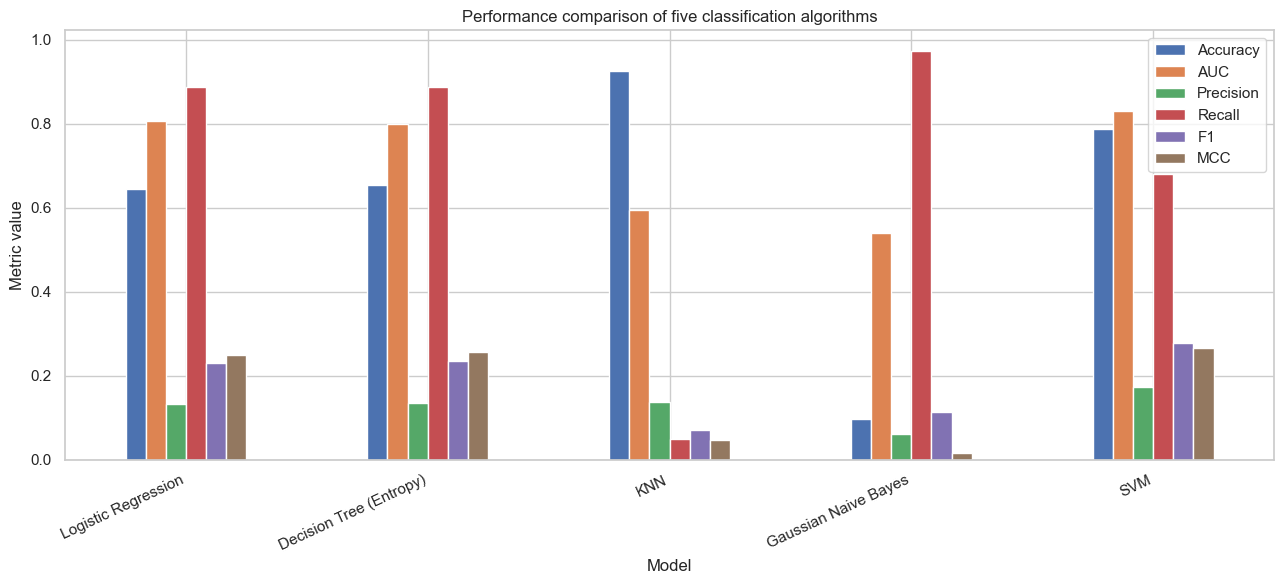

In [32]:
model_results.set_index("Model")[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].plot(
    kind="bar", figsize=(13, 6)
)
plt.title("Performance comparison of five classification algorithms")
plt.ylabel("Metric value")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

<a id="part-15"></a>
# <span style="color:#C00000">15. CONFUSION MATRICES AND ROC CURVES</span>

The confusion matrix separates correct and incorrect classifications. For this problem, false negatives are fraudulent claims predicted as non-fraud, while false positives are genuine claims predicted as fraud. ROC curves show the trade-off between true-positive and false-positive rates across thresholds.

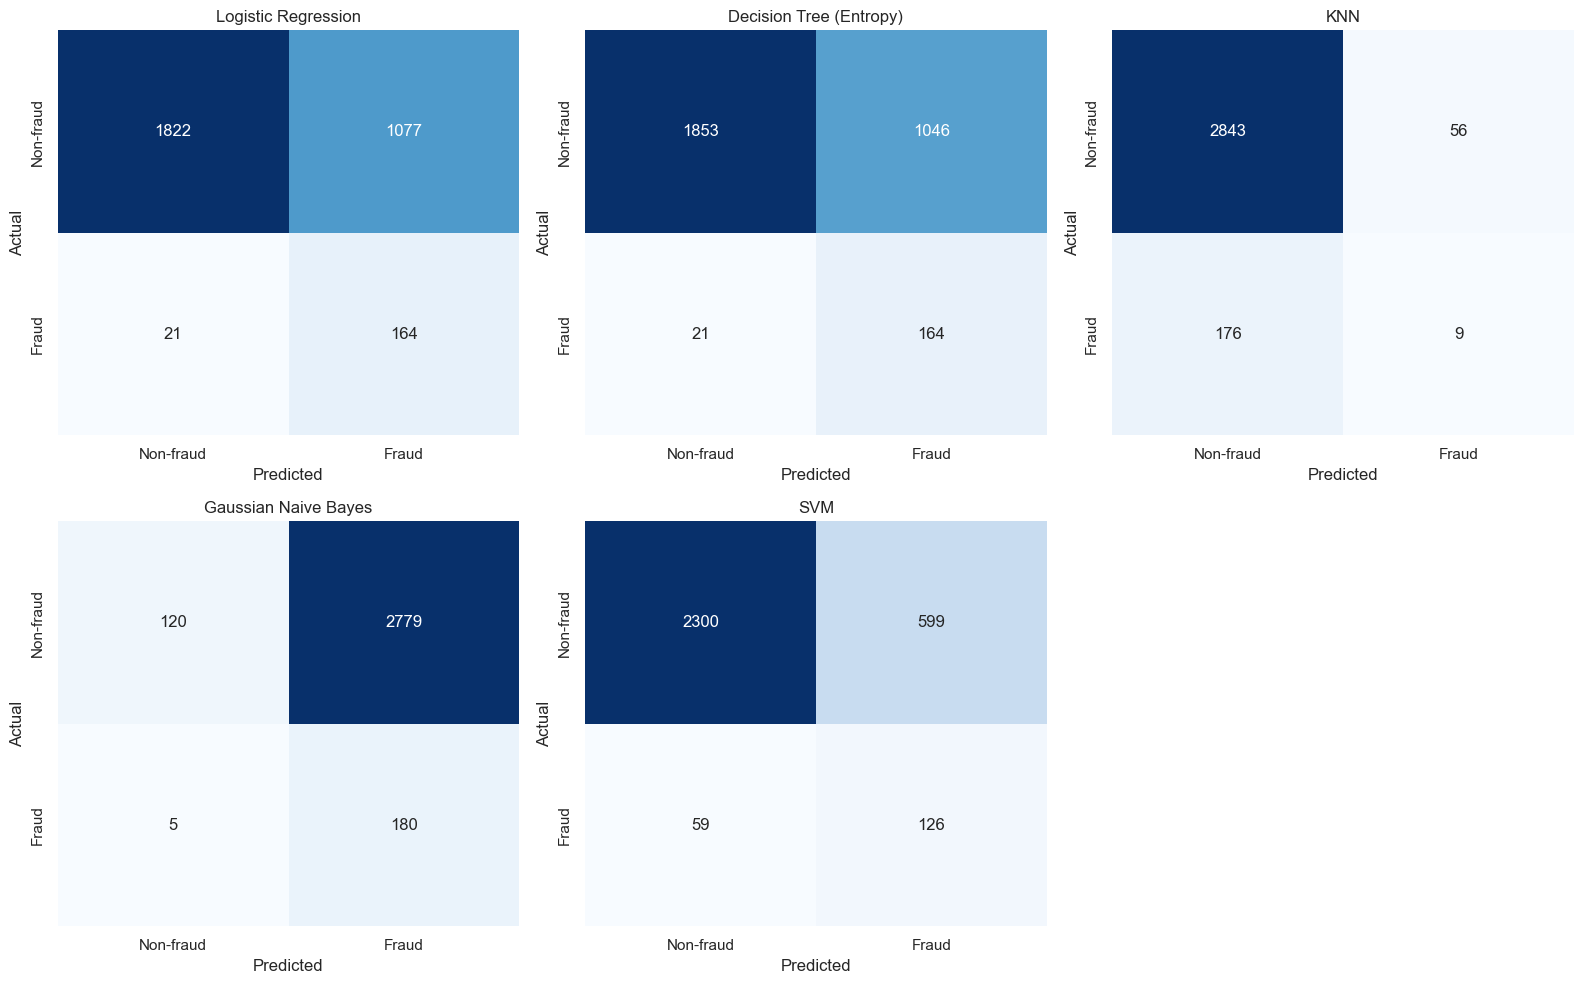

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for position, (model_label, (_, predicted_labels, _)) in enumerate(trained_models.items()):
    matrix = confusion_matrix(y_test, predicted_labels, labels=[0, 1])
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Non-fraud", "Fraud"],
        yticklabels=["Non-fraud", "Fraud"],
        ax=axes[position]
    )
    axes[position].set_title(model_label)
    axes[position].set_xlabel("Predicted")
    axes[position].set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

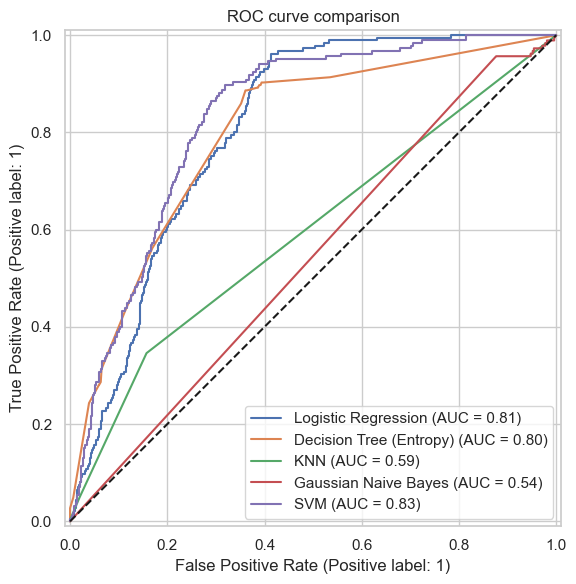

In [34]:
plt.figure(figsize=(8, 6))
for model_label, (_, _, fraud_scores) in trained_models.items():
    RocCurveDisplay.from_predictions(
        y_test, fraud_scores, name=model_label, ax=plt.gca()
    )
plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.title("ROC curve comparison")
plt.tight_layout()
plt.show()

In [35]:
for model_label, (_, predicted_labels, _) in trained_models.items():
    print("\n" + "=" * 65)
    print(model_label)
    print("=" * 65)
    print(classification_report(
        y_test, predicted_labels,
        target_names=["Non-fraud", "Fraud"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

   Non-fraud       0.99      0.63      0.77      2899
       Fraud       0.13      0.89      0.23       185

    accuracy                           0.64      3084
   macro avg       0.56      0.76      0.50      3084
weighted avg       0.94      0.64      0.74      3084


Decision Tree (Entropy)
              precision    recall  f1-score   support

   Non-fraud       0.99      0.64      0.78      2899
       Fraud       0.14      0.89      0.24       185

    accuracy                           0.65      3084
   macro avg       0.56      0.76      0.51      3084
weighted avg       0.94      0.65      0.74      3084


KNN
              precision    recall  f1-score   support

   Non-fraud       0.94      0.98      0.96      2899
       Fraud       0.14      0.05      0.07       185

    accuracy                           0.92      3084
   macro avg       0.54      0.51      0.52      3084
weighted avg       0.89

<a id="part-16"></a>
# <span style="color:#C00000">16. SAVE MODELS AND TEST DATA</span>

The complete pipeline is saved for each classifier, including preprocessing and the fitted estimator. This is important because the Streamlit application must apply the same transformations used during training.

The labelled test CSV is retained so that the Streamlit application can calculate evaluation metrics. Do not use this test file as training data.

In [36]:
model_folder = PROJECT_DIR / "model"
compatibility_model_folder = PROJECT_DIR / "models"
output_folder = PROJECT_DIR / "outputs"
data_folder = PROJECT_DIR / "data"

model_folder.mkdir(exist_ok=True)
compatibility_model_folder.mkdir(exist_ok=True)
output_folder.mkdir(exist_ok=True)

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree (Entropy)": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

for model_label, (fitted_model, _, _) in trained_models.items():
    joblib.dump(fitted_model, model_folder / model_file_names[model_label])
    # Keep a second copy for compatibility with the companion Streamlit app.
    joblib.dump(fitted_model, compatibility_model_folder / model_file_names[model_label])
    print("Saved:", model_file_names[model_label])

model_results.to_csv(output_folder / "model_comparison.csv", index=False)

test_records = X_test.copy()
test_records[TARGET] = y_test.values
test_records.to_csv(data_folder / "test_data.csv", index=False)

print("\nComparison table saved.")
print("Labelled test data saved.")
print("Model files saved in:", model_folder)
print("Streamlit-compatible copies saved in:", compatibility_model_folder)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib

Comparison table saved.
Labelled test data saved.
Model files saved in: d:\ML-Assignment2-2025NS04074\1_ML-Assignment2-2025NS04074-Final\model
Streamlit-compatible copies saved in: d:\ML-Assignment2-2025NS04074\1_ML-Assignment2-2025NS04074-Final\models


In [37]:
print("Saved model files:")
for saved_file in sorted(model_folder.glob("*.joblib")):
    print(saved_file.name, "-", f"{saved_file.stat().st_size:,}", "bytes")

print("\nOutput files:")
for saved_file in sorted(output_folder.glob("*")):
    print(saved_file.name)

Saved model files:
decision_tree.joblib - 23,233 bytes
knn.joblib - 14,619,676 bytes
logistic_regression.joblib - 15,111 bytes
naive_bayes.joblib - 18,511 bytes
svm.joblib - 7,325,891 bytes

Output files:
.gitkeep
model_comparison.csv


### 17.1 Results summary and evidence-based interpretation

The following cell derives the model ranking and observations directly from the metrics calculated in this run. No performance values are hard-coded.

In [38]:
# Rank models by F1, then MCC, then ROC-AUC. This gives priority to the positive-class
# precision/recall balance while using two further measures as tie-breakers.
ranked_results = model_results.sort_values(
    by=["F1", "MCC", "AUC"], ascending=False
).reset_index(drop=True)

best_f1 = ranked_results.iloc[0]
best_recall = model_results.loc[model_results["Recall"].idxmax()]
best_precision = model_results.loc[model_results["Precision"].idxmax()]
best_auc = model_results.loc[model_results["AUC"].idxmax()]
best_mcc = model_results.loc[model_results["MCC"].idxmax()]

print("MODEL RANKING (F1, then MCC, then AUC)")
display(ranked_results.style.format({
    "Accuracy":"{:.4f}", "AUC":"{:.4f}", "Precision":"{:.4f}",
    "Recall":"{:.4f}", "F1":"{:.4f}", "MCC":"{:.4f}"
}))
print(f"Highest F1 candidate: {best_f1['Model']} (F1={best_f1['F1']:.4f})")
print(f"Highest recall: {best_recall['Model']} (Recall={best_recall['Recall']:.4f})")
print(f"Highest precision: {best_precision['Model']} (Precision={best_precision['Precision']:.4f})")
print(f"Highest ROC-AUC: {best_auc['Model']} (AUC={best_auc['AUC']:.4f})")
print(f"Highest MCC: {best_mcc['Model']} (MCC={best_mcc['MCC']:.4f})")

# Per-model narrative generated from observed scores.
for _, row in model_results.iterrows():
    print(
        f"{row['Model']}: accuracy {row['Accuracy']:.3f}, "
        f"precision {row['Precision']:.3f}, recall {row['Recall']:.3f}, "
        f"F1 {row['F1']:.3f}, AUC {row['AUC']:.3f}, MCC {row['MCC']:.3f}."
    )

print("\\nInterpretation:")
print(
    f"{best_f1['Model']} is the leading candidate under the stated F1-first "
    f"ranking (F1={best_f1['F1']:.3f}, MCC={best_f1['MCC']:.3f}, "
    f"AUC={best_f1['AUC']:.3f}). This is a comparative result on this "
    "held-out split, not evidence of production suitability."
)
print(
    f"{best_recall['Model']} has the highest fraud recall "
    f"({best_recall['Recall']:.3f}); check its precision and false-positive "
    "count before considering it for an investigation queue."
)
print(
    f"{best_precision['Model']} has the highest fraud precision "
    f"({best_precision['Precision']:.3f}); compare its recall to understand "
    "how many fraud cases it misses."
)

MODEL RANKING (F1, then MCC, then AUC)


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.7866,0.8290,0.1738,0.6811,0.2769,0.2657
1,Decision Tree (Entropy),0.6540,0.7979,0.1355,0.8865,0.2351,0.2557
2,Logistic Regression,0.6440,0.8063,0.1322,0.8865,0.2300,0.2494
3,Gaussian Naive Bayes,0.0973,0.5387,0.0608,0.9730,0.1145,0.0173
4,KNN,0.9248,0.5948,0.1385,0.0486,0.0720,0.0485


Highest F1 candidate: SVM (F1=0.2769)
Highest recall: Gaussian Naive Bayes (Recall=0.9730)
Highest precision: SVM (Precision=0.1738)
Highest ROC-AUC: SVM (AUC=0.8290)
Highest MCC: SVM (MCC=0.2657)
Logistic Regression: accuracy 0.644, precision 0.132, recall 0.886, F1 0.230, AUC 0.806, MCC 0.249.
Decision Tree (Entropy): accuracy 0.654, precision 0.136, recall 0.886, F1 0.235, AUC 0.798, MCC 0.256.
KNN: accuracy 0.925, precision 0.138, recall 0.049, F1 0.072, AUC 0.595, MCC 0.048.
Gaussian Naive Bayes: accuracy 0.097, precision 0.061, recall 0.973, F1 0.115, AUC 0.539, MCC 0.017.
SVM: accuracy 0.787, precision 0.174, recall 0.681, F1 0.277, AUC 0.829, MCC 0.266.
\nInterpretation:
SVM is the leading candidate under the stated F1-first ranking (F1=0.277, MCC=0.266, AUC=0.829). This is a comparative result on this held-out split, not evidence of production suitability.
Gaussian Naive Bayes has the highest fraud recall (0.973); check its precision and false-positive count before considering

### 17.2 Export the experiment results and project summary

This section writes the measured comparison table and a README containing the problem definition, dataset profile, model metrics and results-based observations. Re-run this cell after any model or preprocessing change.

In [ ]:
# Save a machine-readable record of the run.
model_results.to_csv(output_folder / "model_comparison.csv", index=False)

run_details = {
    "dataset_file": "data/fraud_oracle.csv",
    "dataset_rows": int(claims.shape[0]),
    "dataset_columns_including_target": int(claims.shape[1]),
    "predictor_count_after_identifier_exclusion": int(X.shape[1]),
    "target": TARGET,
    "target_distribution": {str(k): int(v) for k, v in y.value_counts().sort_index().items()},
    "test_size": 0.20,
    "random_state": RANDOM_STATE,
    "knn_selected_k": int(knn_search.best_params_["classifier__n_neighbors"]),
    "model_selection_rule": "Highest F1; tie-break by MCC, then ROC-AUC",
    "models": {
        label: {
            "Accuracy": float(row["Accuracy"]), "AUC": float(row["AUC"]),
            "Precision": float(row["Precision"]), "Recall": float(row["Recall"]),
            "F1": float(row["F1"]), "MCC": float(row["MCC"])
        }
        for label, row in model_results.set_index("Model").iterrows()
    }
}
(output_folder / "run_metadata.json").write_text(
    json.dumps(run_details, indent=2), encoding="utf-8"
)

metric_table = model_results.to_string(index=False, float_format=lambda value: f"{value:.4f}")
winner = ranked_results.iloc[0]
observations = []
for _, row in model_results.iterrows():
    observations.append(
        f"- **{row['Model']}:** Accuracy {row['Accuracy']:.4f}, AUC "
        f"{row['AUC']:.4f}, Precision {row['Precision']:.4f}, Recall "
        f"{row['Recall']:.4f}, F1 {row['F1']:.4f}, MCC {row['MCC']:.4f}. "
        + ("This model ranked first under the F1/MCC/AUC selection rule."
           if row["Model"] == winner["Model"] else
           "Its results should be interpreted alongside the fraud-class precision and recall.")
    )

readme_text = f'''# Vehicle Insurance Claim Fraud Detection

## Problem statement
This project evaluates whether historical vehicle insurance claim records can be classified as potentially fraudulent (`FraudFound_P = 1`) or non-fraudulent (`FraudFound_P = 0`). The output is intended only as a screening signal to support human review; it is not proof of fraud and must not be used for automatic claim rejection.

## Dataset description
- Source: [Kaggle – Vehicle Claim Fraud Detection](https://www.kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection)
- Records: {claims.shape[0]:,}
- Columns including target: {claims.shape[1]}
- Predictors used: {X.shape[1]} (the target and `PolicyNumber` identifier are excluded)
- Target: `FraudFound_P` (0 = non-fraud, 1 = fraud)
- Class counts: non-fraud = {int((y == 0).sum()):,}; fraud = {int((y == 1).sum()):,}
- Split: stratified 80:20; random state = {RANDOM_STATE}

This is a historical vehicle-insurance dataset. It is not proprietary data from ICICI Lombard and is not described as an Indian insurer dataset.

## GitHub repository
Add the public repository URL here after creating and verifying the repository.

## Models and evaluation metrics
All five classifiers use the same training/test split. Metrics are calculated for the fraud class as the positive class. AUC is binary ROC-AUC.

{metric_table}

## Model observations
{chr(10).join(observations)}

## Overall model selection
The highest-ranked model under the pre-defined rule (F1, followed by MCC and AUC) is **{winner['Model']}** (F1 = {winner['F1']:.4f}, MCC = {winner['MCC']:.4f}, AUC = {winner['AUC']:.4f}). This ranking is specific to this dataset and held-out split. The model should be treated as a candidate for further validation, not a production-ready fraud decision system.

## Repository contents
- `notebooks/Vehicle_Insurance_Fraud_Detection.ipynb`
- `src/train_models.py`
- `app.py`
- `requirements.txt`
- `data/test_data.csv`
- `model/` (five fitted preprocessing/classifier pipelines; required repository folder)
- `models/` (duplicate artefacts retained for compatibility with the Streamlit application)
- `outputs/model_comparison.csv`
'''
(PROJECT_DIR / "README.md").write_text(readme_text, encoding="utf-8")
print("Saved model comparison, run metadata and generated README.")
print("README:", PROJECT_DIR / "README.md")

<a id="part-17"></a>
# <span style="color:#C00000">17. FINDINGS, LIMITATIONS AND CONCLUSION</span>

## 17.1 Findings

The model comparison, classification reports, confusion matrices and ROC curves above provide the evidence for the findings. The result-export cell generates the corresponding README and records the metric values from the current execution.

## 17.2 Limitations

- The dataset is historical and may not represent current insurance processes.
- It is a vehicle insurance dataset and does not represent proprietary data from any specific insurer.
- The fraud class is a small proportion of the records; accuracy alone is not sufficient to assess performance.
- False positives can increase investigation workload, while false negatives represent fraud cases not identified by the model.
- The results from one train/test split do not establish generalisation to another insurer, geography or time period.
- Predictions should only support human review and must not be treated as proof of fraud.

## 17.3 Conclusion

The study compares Logistic Regression, Decision Tree, K-Nearest Neighbours, Gaussian Naive Bayes and Support Vector Machine on a common stratified hold-out set. The final candidate is selected using the observed F1-score, with MCC and ROC-AUC as tie-breakers. The selected model requires further validation and threshold assessment before any operational use.

---

## Final execution checklist

- [ ] Dataset profile and data-quality checks reviewed.
- [ ] Preprocessing fitted using training data only.
- [ ] Same stratified train/test split used for all five models.
- [ ] All five classifiers executed successfully.
- [ ] Accuracy, AUC, Precision, Recall, F1 and MCC calculated for every classifier.
- [ ] Confusion matrices, ROC curves and classification reports reviewed.
- [ ] Five complete model pipelines saved.
- [ ] Labelled `test_data.csv` generated.
- [ ] `outputs/model_comparison.csv` and `outputs/run_metadata.json` generated.
- [ ] README generated from the executed results.
- [ ] Streamlit application tested using the generated test CSV.
- [ ] BITS Virtual Lab execution evidence captured separately.## 17.4 Submission evidence

The assignment submission PDF must contain, in order:
1. Clickable GitHub repository link, with source code, `requirements.txt`, `README.md`, labelled `test_data.csv` and the `model/` directory.
2. Clickable live Streamlit Community Cloud application link.
3. One screenshot showing the assignment execution in BITS Virtual Lab.
4. The complete README content, including the problem statement, dataset description, repository link, six-metric comparison table, model-wise observations and overall winner.

The BITS Virtual Lab screenshot and live deployment link are captured outside this notebook after the application has been deployed and tested.